# 03 · Models and evaluation

**Indoor Location Prediction Using Wi-Fi Signals** (Project 9) · Team T084

The four models, their tuning, the final-model choice, the test results and where the remaining
error comes from. All numbers are read from results/; no model is trained here.

## 1. Four models and what we tuned

**What:** each model predicts building, floor and position with three separate models: Baseline RF
(300 trees, default settings, rssi+stats, not tuned), kNN (rssi), Random Forest and XGBoost (both
rssi+stats+affinity).

**Why:** the Baseline RF is the bar to beat, kNN is the classic fingerprinting method (it uses the
most similar stored scans), and tree ensembles can combine many weak hints such as AP-affinity.

**Result:** with 5-fold user-group cross-validation (CV), each task picked its own best setting,
e.g. kNN uses 1 neighbor for building, 5 for floor and 3 for position.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from indoorloc import config, plots

plt.rcParams["figure.dpi"] = 150  # larger figures in the notebook
metrics_dir = config.RESULTS_DIR / "metrics"
best = json.loads((config.RESULTS_DIR / "tuning" / "best_params.json").read_text())
for family, grid in config.GRIDS.items():
    print(f"{config.MODEL_NAMES[family]} ({config.MODEL_FEATURES[family]}), grid {grid}")
    for task, setting in best[family].items():
        print(f"    best for {task}: {setting}")

kNN (rssi), grid {'n_neighbors': [1, 3, 5, 7, 9, 11, 15], 'weights': ['uniform', 'distance'], 'metric': ['euclidean', 'manhattan']}
    best for building: {'n_neighbors': 1, 'weights': 'uniform', 'metric': 'euclidean'}
    best for floor: {'n_neighbors': 5, 'weights': 'uniform', 'metric': 'manhattan'}
    best for position: {'n_neighbors': 3, 'weights': 'distance', 'metric': 'euclidean'}
Random Forest (rssi+stats+affinity), grid {'max_features': ['sqrt', 0.2, 0.5], 'min_samples_leaf': [1, 4]}
    best for building: {'max_features': 'sqrt', 'min_samples_leaf': 1}
    best for floor: {'max_features': 0.5, 'min_samples_leaf': 4}
    best for position: {'max_features': 0.5, 'min_samples_leaf': 1}
XGBoost (rssi+stats+affinity), grid {'max_depth': [4, 6, 10], 'n_estimators': [300, 600]}
    best for building: {'max_depth': 4, 'n_estimators': 300}
    best for floor: {'max_depth': 4, 'n_estimators': 300}
    best for position: {'max_depth': 10, 'n_estimators': 600}


## 2. One tuning table: Random Forest, position

**What:** the CV mean 2D error (straight-line distance between predicted and true position) of the
six Random Forest settings for the position task.

**Why:** every grid was scored like this on the same folds; the lowest CV error (for building and
floor, the highest CV accuracy) wins.

**Result:** max_features 0.5 with min_samples_leaf 1 is chosen (11.09 m); "sqrt" with
min_samples_leaf 4 is the worst (13.06 m).

In [2]:
pd.read_csv(config.RESULTS_DIR / "tuning" / "rf_position.csv")

,max_features,min_samples_leaf,cv_mean,cv_std,chosen
0,sqrt,1,12.0214,4.3248,False
1,sqrt,4,13.0592,4.3912,False
2,0.2,1,11.2620,4.1906,False
3,0.2,4,11.5587,4.3732,False
4,0.5,1,11.0926,4.0099,True
5,0.5,4,11.1874,3.9795,False


## 3. CV results and the final model

**What:** the CV scores (mean and standard deviation over the 5 folds) of the four models, and our
rule, fixed before the test set was used: the final model is the tuned model with the lowest CV
mean 2D error.

**Why:** choosing on the test set would make its score look better than it is.

**Result:** Random Forest (11.09 m) is chosen, just ahead of XGBoost (11.25 m, a gap far smaller
than the spread over the folds), while XGBoost has the best CV floor accuracy (85.4% vs 83.6%).

In [3]:
cv_results = pd.read_csv(metrics_dir / "cv_results.csv")
final = json.loads((metrics_dir / "final_model.json").read_text())
print(f"Rule: {final['rule']} -> {final['name']}")
cv_results

Rule: lowest CV mean 2D error among kNN, Random Forest and XGBoost -> Random Forest


,model,name,building_acc,building_acc_std,floor_acc,floor_acc_std,mean_2d,mean_2d_std
0,baseline_rf,Baseline RF,0.9965,0.0037,0.7799,0.1565,15.8709,4.8976
1,knn,kNN,0.9929,0.0115,0.8238,0.0933,12.7517,6.6476
2,rf,Random Forest,0.9966,0.0056,0.8355,0.1230,11.0926,4.0099
3,xgb,XGBoost,0.9934,0.0098,0.8538,0.1048,11.2493,3.1763


## 4. Test results

**What:** each model is fitted on all 18,719 cleaned training scans and predicts the 1,111 test
scans (the UCI file validationData.csv) once; the figure puts each model's CV score next to its
test score.

**Why:** the test set is used only here, after every choice was made.

**Result:** Random Forest gets every building right, 92.2% of floors and the lowest mean 2D error:
7.42 m (median 5.34 m). XGBoost gets more floors right (95.2%) but has a larger mean 2D error
(7.86 m). For every model, user-group CV is stricter than the test set (figure). Errors are in
Web-Mercator meters; one such meter is about 0.77 m on the ground.

,model,name,building_acc,floor_acc,mae_x,mae_y,mean_2d,median_2d
0,baseline_rf,Baseline RF,0.9982,0.9118,8.6817,7.3997,12.5188,7.7044
1,knn,kNN,0.9982,0.8749,6.1224,5.7046,9.2212,5.8812
2,rf,Random Forest,1.0000,0.9217,4.7738,4.6393,7.4185,5.3402
3,xgb,XGBoost,1.0000,0.9523,5.1833,4.7663,7.8633,6.1854


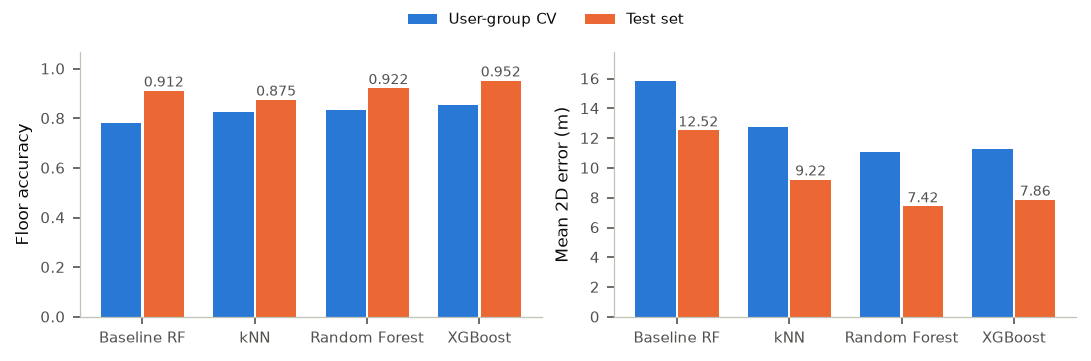

In [4]:
test_results = pd.read_csv(metrics_dir / "test_results.csv")
fig = plots.model_comparison(cv_results, test_results)
test_results

## 5. Where the final model's error comes from

**What:** Random Forest's test scans in three cases (building wrong / building right but floor
wrong / both right), and on phones seen in training vs new phones.

**Why:** to see what is left to fix.

**Result:** no building is wrong. The 87 floor-wrong scans (7.8%) have larger errors (13.06 m vs
6.94 m) but cause only 13.8% of the total error, so 86.2% comes from scans with building and floor
right. New phones have larger errors (8.30 m vs 5.84 m).

In [5]:
breakdown = pd.read_csv(metrics_dir / "error_breakdown.csv")
phones = pd.read_csv(metrics_dir / "per_phone.csv")
display(breakdown[breakdown["model"] == final["final_model"]])
phones[phones["model"] == final["final_model"]]

,model,case,n_scans,share_of_scans,mean_2d,share_of_error
6,rf,building wrong,0,0.0000,NaN,0.0000
7,rf,"building right, floor wrong",87,0.0783,13.0604,0.1379
8,rf,both right,1024,0.9217,6.9391,0.8621


,model,phones,n_phones,n_scans,floor_acc,mean_2d
4,rf,seen in training,2,397,0.9370,5.8350
5,rf,new,9,714,0.9132,8.2989


## 6. Floor confusion and error map of the final model

**What:** true vs predicted floor in each building, and the true test positions (gray) with the
predictions colored by their 2D error.

**Why:** to see which floors get mixed up and where the large errors are.

**Result:** nearly all floor mistakes are one floor up or down, most often in building 1 (29 scans
on floor 1 predicted as floor 2). Large errors (dark points) are more common in buildings 1 and 2,
and some predictions land between corridors, e.g. inside the ring of building 2.

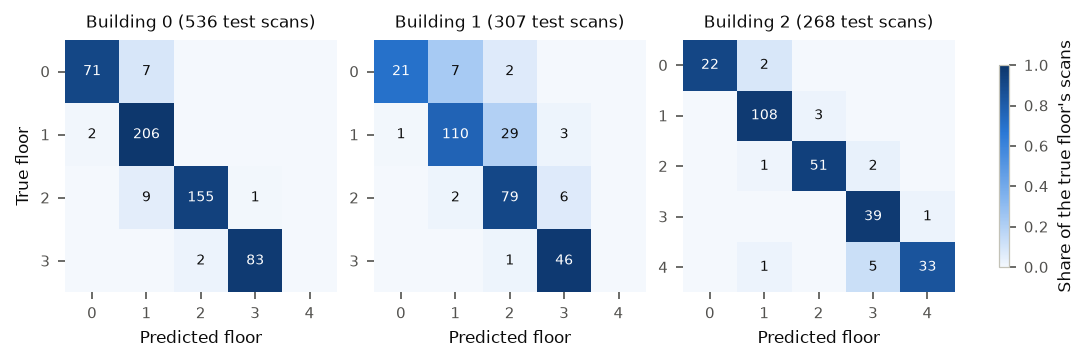

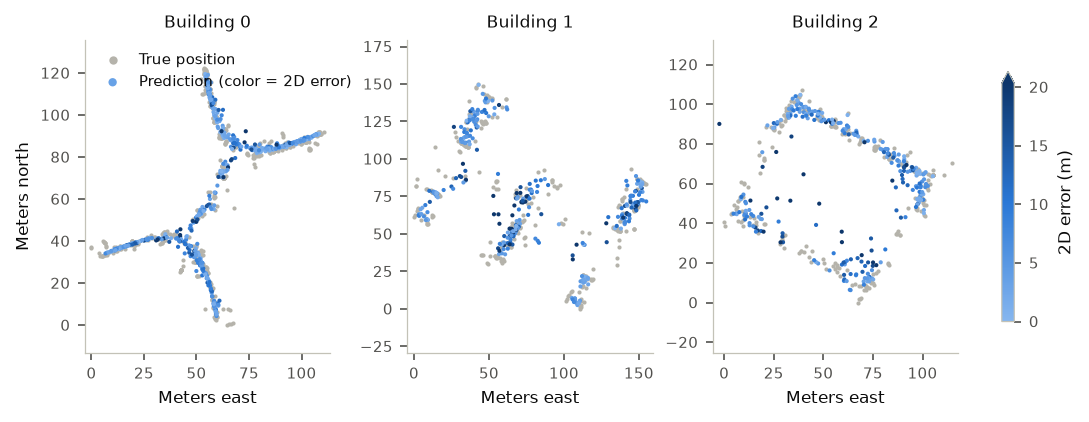

In [6]:
confusion = pd.read_csv(metrics_dir / "floor_confusion.csv")
predictions = pd.read_csv(config.RESULTS_DIR / "predictions" / f"{final['final_model']}.csv")
fig_confusion = plots.floor_confusion(confusion)
fig_map = plots.error_map(predictions)

## 7. The gap Phase 2 addresses

Our three task models are separate and share nothing, and no single model is best at every task:
Random Forest has the lowest mean 2D error (7.42 m), but XGBoost gets more floors right (95.2% vs
92.2%). AP-affinity, a hand-made way of sharing location knowledge between the tasks, cut the CV
mean 2D error of the Baseline RF settings from 15.87 m to 11.38 m (notebook 02). Most of the
remaining error is position within the right floor (86.2% of the total), and new phones are harder.
Phase 2 will train one multi-task neural network that learns building, floor and position together
(shared layers, three output heads), with the same split, test set and metrics, and compare it with
these Phase 1 models.

## Summary

- The final model, chosen by user-group CV before the test set was used, is Random Forest: 100% of
  buildings, 92.2% of floors and a mean 2D error of 7.42 m on the test set.
- No model is best at everything: XGBoost gets more floors right (95.2%), and all three tuned models
  beat the Baseline RF on position (12.52 m).
- Random CV would have promised the Baseline RF 3.67 m (test set: 12.52 m; notebook 01); most of
  the remaining error is position within the right floor and on new phones, and Phase 2 will test
  whether one shared multi-task network does better.